In [6]:
import numpy as np
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from skimage.transform import resize

from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.models import Model
from keras.applications import ResNet50
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.optimizers import Adamax
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


In [7]:
DTRAIN_PATH = ('../data/Training/')
DTEST_PATH = ('../data/Testing/')

X_train = []
Y_train = []

img_rows = 224
img_cols = 224
classes = os.listdir(DTRAIN_PATH)


print(classes)

['glioma', 'meningioma', 'notumor', 'pituitary']


In [8]:
# LOAD DATA

# Load Data Train
for class_name in classes:
    class_path = os.path.join(DTRAIN_PATH, class_name)
    class_num = classes.index(class_name)

    for img_path in os.listdir(class_path):
      img_full_path = plt.imread(os.path.join(class_path, img_path))
      img_resized = resize(img_full_path, (img_rows, img_cols, 3))

      X_train.append(img_resized)
      Y_train.append(class_num)

# Load Data Test

for class_name in classes:
    class_path = os.path.join(DTEST_PATH, class_name)
    class_num = classes.index(class_name)

    for img_path in os.listdir(class_path):
      img_full_path = plt.imread(os.path.join(class_path, img_path))
      img_resized = resize(img_full_path, (img_rows, img_cols, 3))

      X_train.append(img_resized)
      Y_train.append(class_num)


X_train = np.array(X_train)
Y_train = np.array(Y_train)


X_train.shape

(7200, 224, 224, 3)

In [9]:
# Shuffling Data

X_train, Y_train = shuffle(X_train, Y_train, random_state=42)

# Check Data
X_train.shape

(7200, 224, 224, 3)

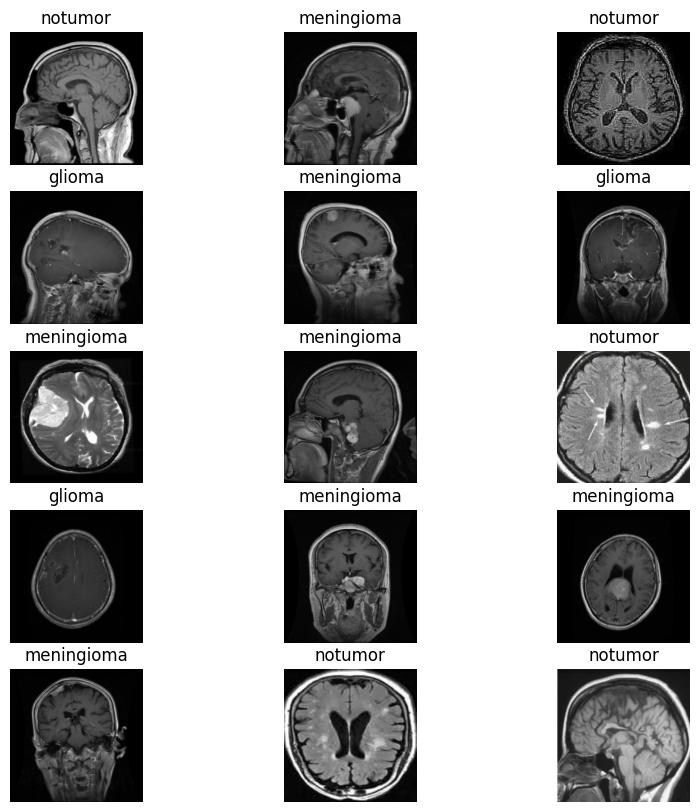

In [10]:
# Plotting Image
# Untuk mengecek apakah sudah sesuai

plt.figure(figsize=(10, 10))

for i in range(15):
  plt.subplot(5, 3, i+1)
  plt.imshow(X_train[i])
  plt.title(classes[Y_train[i]])
  plt.axis('off')

plt.show()

In [11]:
# Splitting Data

X_train, X_test, Y_train, Y_test = train_test_split(X_train, Y_train, test_size=0.2, random_state=42)

X_train, X_val, Y_train, Y_val = train_test_split(X_train, Y_train, test_size=0.1, random_state=42)

In [12]:
# Data Augmentation

data_Augment = ImageDataGenerator(
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

data_Augment.fit(X_train)

# Ubah ke Categorical

y_train_new = to_categorical(Y_train, num_classes=4)
y_val_new = to_categorical(Y_val, num_classes=4)
y_test_new = to_categorical(Y_test, num_classes=4)


In [13]:
# Buat Model

base_model = ResNet50(input_shape=(img_rows, img_cols, 3), include_top=False, weights='imagenet')

for layer in base_model.layers[-30:]:
  layer.trainable = True

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dropout(0.5),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(4, activation='softmax')
])

model.compile(Adamax(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint('Bmodel.h5', monitor='val_loss', save_best_only=True)

model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resnet50 (Functional)       (None, 7, 7, 2048)        23587712  
                                                                 
 global_average_pooling2d (G  (None, 2048)             0         
 lobalAveragePooling2D)                                          
                                                                 
 dropout (Dropout)           (None, 2048)              0         
                                                                 
 dense (Dense)               (None, 128)               262272    
                                                                 
 dropout_1 (Dropout)         (None, 128)               0         
                                                                 
 dense_1 (Dense)             (None, 4)                 516       
                                                        

In [14]:
print("X_train:", X_train.shape, "Y_train:", Y_train.shape)
print("X_val:  ", X_val.shape,   "Y_val:  ", Y_val.shape)
print("Output shape:", model.output_shape)

X_train: (5184, 224, 224, 3) Y_train: (5184,)
X_val:   (576, 224, 224, 3) Y_val:   (576,)
Output shape: (None, 4)


In [15]:
# Training the Model

history = model.fit(data_Augment.flow(X_train, y_train_new, batch_size=32), epochs=50, validation_data=(X_val, y_val_new), callbacks=[early_stopping, checkpoint])

Epoch 1/50
162/162 [==============================] - 811s 5s/step - loss: 0.7936 - accuracy: 0.6962 - val_loss: 1.5008 - val_accuracy: 0.2500
Epoch 2/50
162/162 [==============================] - 760s 5s/step - loss: 0.3715 - accuracy: 0.8671 - val_loss: 1.4650 - val_accuracy: 0.3420
Epoch 3/50
162/162 [==============================] - 2123s 13s/step - loss: 0.2790 - accuracy: 0.9053 - val_loss: 1.3434 - val_accuracy: 0.4201
Epoch 4/50
162/162 [==============================] - 863s 5s/step - loss: 0.2299 - accuracy: 0.9217 - val_loss: 1.2080 - val_accuracy: 0.5469
Epoch 5/50
162/162 [==============================] - 756s 5s/step - loss: 0.1922 - accuracy: 0.9375 - val_loss: 1.1989 - val_accuracy: 0.6181
Epoch 6/50
162/162 [==============================] - 756s 5s/step - loss: 0.1588 - accuracy: 0.9460 - val_loss: 0.4499 - val_accuracy: 0.8368
Epoch 7/50
162/162 [==============================] - 753s 5s/step - loss: 0.1441 - accuracy: 0.9541 - val_loss: 0.2235 - val_accuracy: 0.90

In [16]:
# Save the Model

model = load_model('Bmodel.h5')

45/45 [==============================] - 60s 1s/step - loss: 0.0486 - accuracy: 0.9833


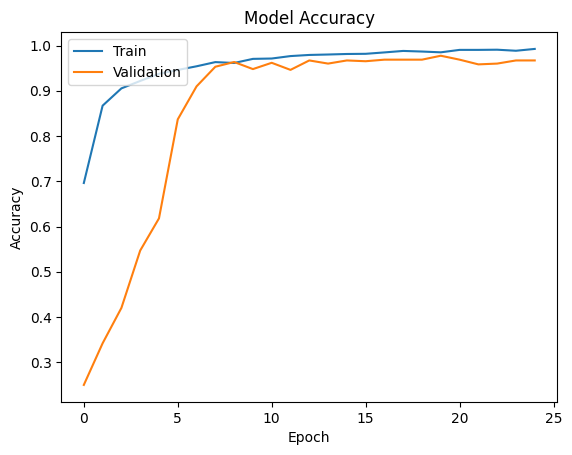

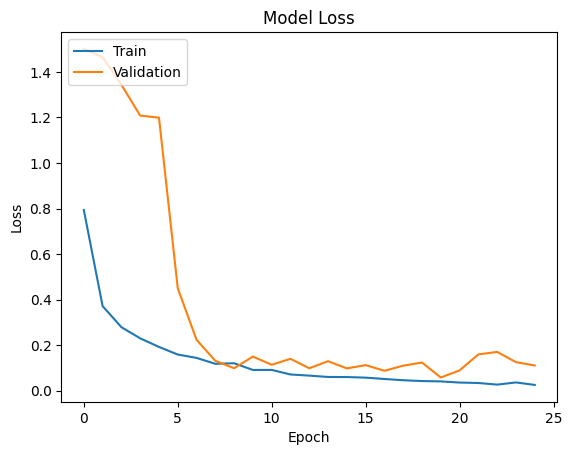

In [18]:
# Visualization

model.evaluate(X_test, y_test_new)

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

45/45 [==============================] - 76s 2s/step


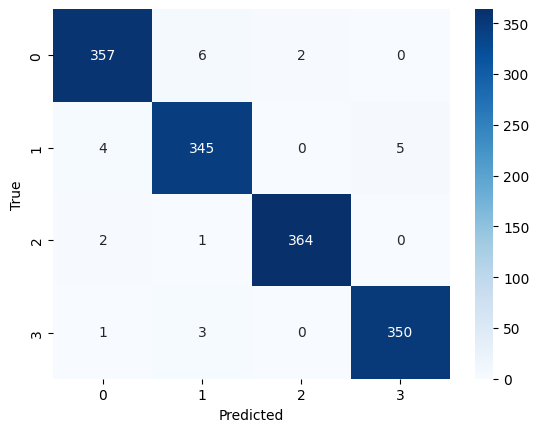

In [21]:
# Confusion Matrix

y_pred =  model.predict(X_test)
y_pred = np.argmax(y_pred, axis=1)

conf_m = confusion_matrix(Y_test, y_pred)
sns.heatmap(conf_m, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

              precision    recall  f1-score   support

      glioma       0.98      0.98      0.98       365
  meningioma       0.97      0.97      0.97       354
     notumor       0.99      0.99      0.99       367
   pituitary       0.99      0.99      0.99       354

    accuracy                           0.98      1440
   macro avg       0.98      0.98      0.98      1440
weighted avg       0.98      0.98      0.98      1440



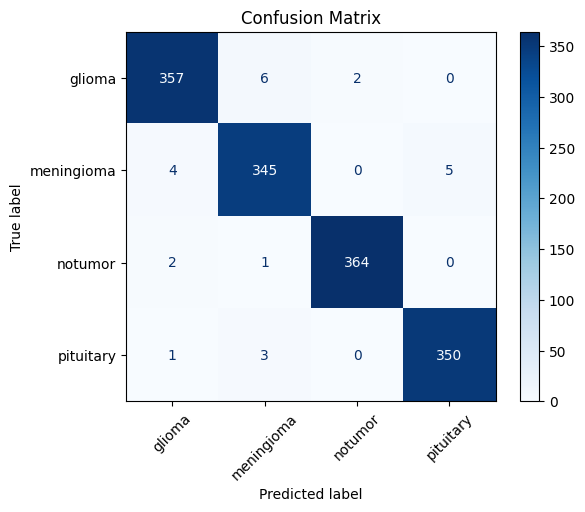

[0.9600694179534912, 0.9670138955116272, 0.9670138955116272]
[0.17036989331245422, 0.12528590857982635, 0.11094287037849426]


In [22]:
# Classification Report

from sklearn.metrics import ConfusionMatrixDisplay
print(classification_report(Y_test, y_pred, target_names=classes))

conf_m = confusion_matrix(Y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_m, display_labels=classes)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix")
plt.show()

print(history.history["val_accuracy"][-3:])
print(history.history["val_loss"][-3:])

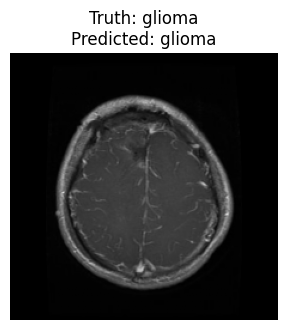

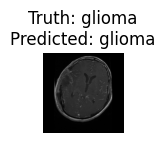

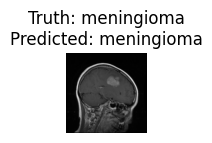

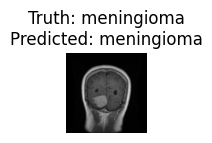

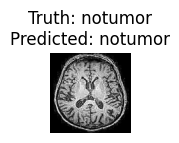

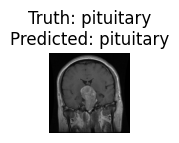

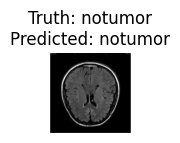

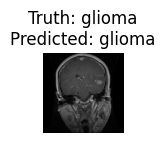

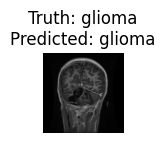

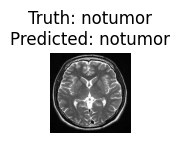

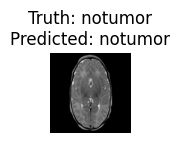

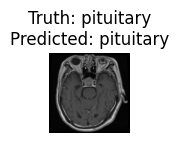

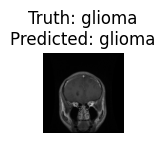

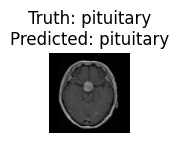

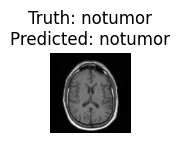

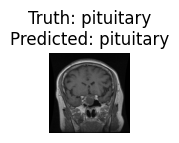

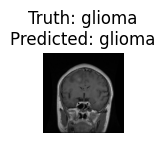

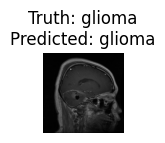

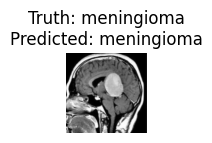

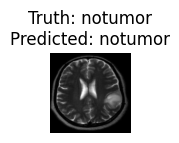

In [25]:
# Visualization Model Predictions

plt.figure(figsize=(20, 20))

for i in range(20):
  plt.subplot(4, 5, i+1)
  plt.imshow(X_test[i])
  plt.title(f"Truth: {classes[Y_test[i]]}\nPredicted: {classes[y_pred[i]]}")
  plt.axis('off')
  plt.show()